<a href="https://colab.research.google.com/github/kaue-cruz123/Trabalho-computacional---Visualiza-o-e-explora-o-de-dados/blob/main/Trabalho_Computacional_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files

uploaded = files.upload()

In [ ]:
#Parte 1

import pandas as pd
import numpy as np
colunas = ['age','sex','cp','trestbps','chol','fbs',
           'restecg','thalach','exang','oldpeak','slope','ca','thal','target']

df = pd.read_csv('processed.cleveland.data', header=None, names=colunas)

In [ ]:
print(df.head())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  target  
0    3.0  0.0  6.0       0  
1    2.0  3.0  3.0       2  
2    2.0  2.0  7.0       1  
3    3.0  0.0  3.0       0  
4    1.0  0.0  3.0       0  


#Pré processamento

1. Remoção de valores ausentes



In [ ]:

print("Valores ausentes:")
print(df.isnull().sum())

Valores ausentes:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
df.replace("?", np.nan, inplace=True)

print("Valores Ausentes após alteração:")
print(df.isnull().sum())

Valores Ausentes após alteração:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [ ]:
print("Valores Ausentes após remoção:")
print(f"df antes da remoção: {df.shape}")
print(df.isnull().sum())

df = df.dropna()
print(f"df após a remoção: {df.shape}")
print(df.isnull().sum())


Valores Ausentes após remoção:
df antes da remoção: (303, 14)
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
df após a remoção: (297, 14)
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


2. Tipos das variáveis e verificação de possíveis inconsistências

In [ ]:
print(df.dtypes)

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
target        int64
dtype: object


In [ ]:
print("Visão geral do arquivo")
print(df.shape)
print(df.head())

print("Estatistica:")
print(df.describe())

print("Linhas duplicadas:")
print(df.duplicated().sum())

for col in df.select_dtypes(include='object').columns:
    print(f"\n[{col}] valores únicos: {df[col].unique()}") #Verificar se os dados estão tratados


Visão geral do arquivo
(297, 14)
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  target  
0    3.0  0.0  6.0       0  
1    2.0  3.0  3.0       2  
2    2.0  2.0  7.0       1  
3    3.0  0.0  3.0       0  
4    1.0  0.0  3.0       0  
Estatistica:
              age         sex          cp    trestbps        chol         fbs  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   
std      9.049736    0.468500    0.964859   17.762806   51.997583    0.352

In [ ]:
df = df.iloc[:, [0, 1, 7, 13]]

df.columns = ['age', 'sex', 'thalach', 'target']

df['target'] = df['target'].map(lambda x: 0 if x == 0 else 1) #Transformando target

print(df.shape)
print(df.head())
print(df['target'].value_counts())

(297, 4)
    age  sex  thalach  target
0  63.0  1.0    150.0       0
1  67.0  1.0    108.0       1
2  67.0  1.0    129.0       1
3  37.0  1.0    187.0       0
4  41.0  0.0    172.0       0
target
0    160
1    137
Name: count, dtype: int64


In [ ]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Linhas duplicadas:")
print(df.duplicated().sum())

Linhas duplicadas:
0


In [ ]:
print(df.isnull().sum())

age        0
sex        0
thalach    0
target     0
dtype: int64


#Parte 1 - Distribuição de frequência

In [ ]:
df = df.sort_values(by='age').reset_index(drop=True)
n = len(df)
minimo = (df['age'].min())
maximo = (df['age'].max())
amplitude = maximo - minimo
k = round(1 + 3.322 * np.log10(n))
h = np.ceil(amplitude / k)

bins = [minimo + i * h for i in range(int(k) + 1)]
labels = [f"{bins[i]} {bins[i+1]}" for i in range(int(k))]

df['classe'] = pd.cut(df['age'], bins=bins, labels=labels, right=False,include_lowest=True)

tabela = df['classe'].value_counts().sort_index().reset_index()
tabela.columns = ['Classe', 'fi']

tabela['xi'] = [(bins[i] + bins [i+1]) / 2 for i in range(int(k))] #Ponto médio

tabela['Fi'] = tabela['fi'].cumsum() #Freq acumulada

tabela['fri'] = (tabela['fi'] / n).round(4) #Freq relativa

tabela['Fri'] = tabela['fri'].cumsum().round(4) #Relativa acumulada

media = (tabela['xi'] * tabela['fi']).sum() / n #Media agrupada

n_2 = n / 2

idx_med = tabela[tabela['Fi'] >= n_2].index[0] # mediana
classe_mediana = tabela.loc[idx_med, 'Classe']
L = bins[idx_med]
Fi_ant = tabela['Fi'].iloc[idx_med - 1] if idx_med > 0 else 0 #Acumulada anterior
fi_med = tabela.loc[idx_med, 'fi'] #Freq classe mediana

mediana = L + ((n_2 - Fi_ant) / fi_med) * h

variancia = ((tabela['fi'] * (tabela['xi'] - media) ** 2).sum()) / n
desvio_padrao = np.sqrt(variancia)

print(tabela.to_string(index=False))

print(f"Média: {media}")
print(f"Mediana:{mediana}")
print(f"Classe mediana: {classe_mediana}")
print(f"Variancia: {variancia}")
print(f"Desvio padrão: {desvio_padrao}")
print(f"Minimo: {minimo}")
print(f"Maximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"N° de classes: {k}")
print(f"Largura da classe: {h}")
print("Total na tabela:", tabela['fi'].sum())


   Classe  fi   xi  Fi    fri    Fri
29.0 35.0   3 32.0   3 0.0102 0.0102
35.0 41.0  14 38.0  17 0.0476 0.0578
41.0 47.0  49 44.0  66 0.1667 0.2245
47.0 53.0  47 50.0 113 0.1599 0.3844
53.0 59.0  77 56.0 190 0.2619 0.6463
59.0 65.0  63 62.0 253 0.2143 0.8606
65.0 71.0  35 68.0 288 0.1190 0.9796
71.0 77.0   5 74.0 293 0.0170 0.9966
77.0 83.0   1 80.0 294 0.0034 1.0000
Média: 55.04081632653061
Mediana:55.64935064935065
Classe mediana: 53.0 59.0
Variancia: 82.46772178259059
Desvio padrão: 9.081174031070574
Minimo: 29.0
Maximo: 77.0
Amplitude: 48.0
N° de classes: 9
Largura da classe: 6.0
Total na tabela: 294


#Parte 2: Visualização

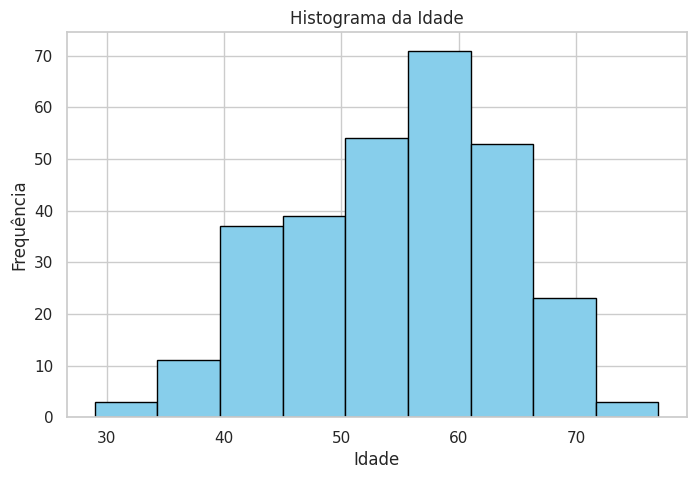


INTERPRETAÇÃO DO HISTOGRAMA:
O gráfico mostra a distribuição das idades dos pacientes.
É possível observar concentração maior entre 50 e 60 anos.


/tmp/ipykernel_5503/275451861.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='target', y='age', data=df, palette='Set2')


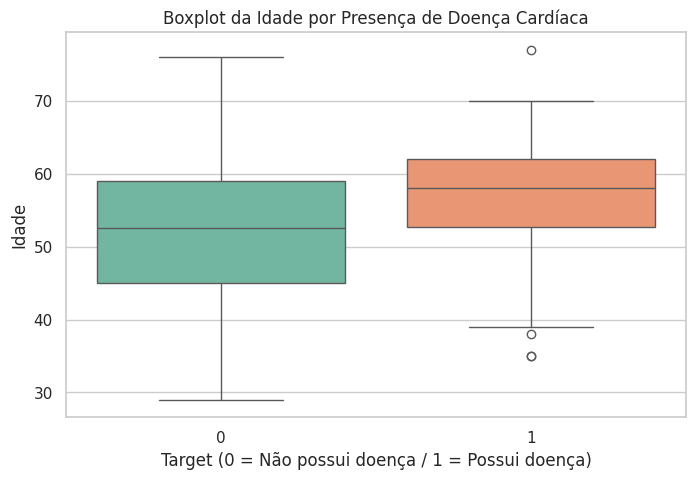


INTERPRETAÇÃO DO BOXPLOT:
O boxplot permite comparar a distribuição das idades entre os grupos.
Também é possível identificar possíveis outliers.


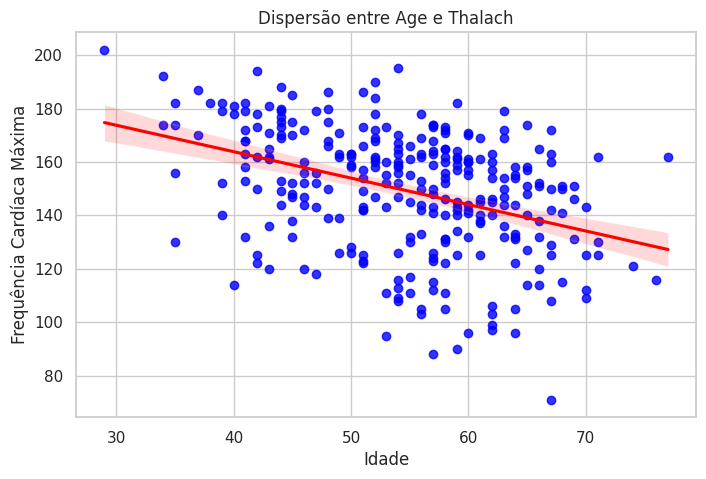


INTERPRETAÇÃO DO GRÁFICO DE DISPERSÃO:
Observa-se tendência negativa entre idade e frequência cardíaca máxima.
Ou seja, pacientes mais velhos tendem a apresentar menor thalach.


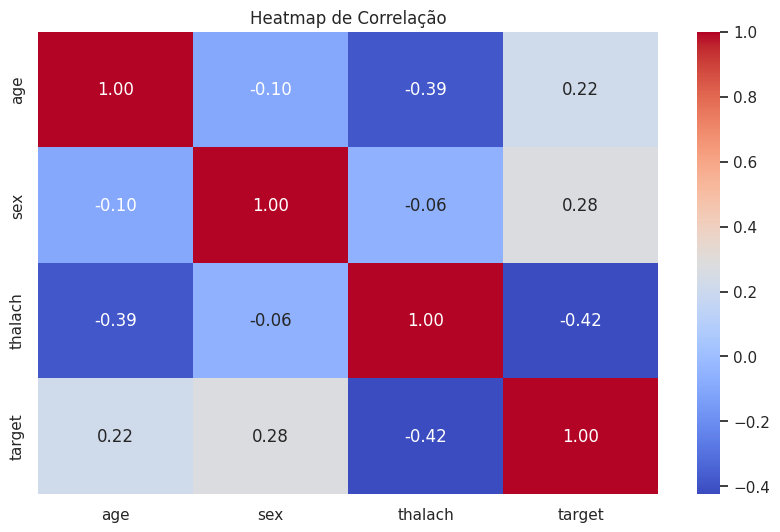


INTERPRETAÇÃO DO HEATMAP:
Valores próximos de 1 indicam correlação positiva forte.
Valores próximos de -1 indicam correlação negativa forte.
Valores próximos de 0 indicam correlação fraca.


In [ ]:
# Parte 2 - Visualização

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set(style='whitegrid')

# 1. Histograma de age

plt.figure(figsize=(8,5))
plt.hist(df['age'], bins=int(k), color='skyblue', edgecolor='black')
plt.title('Histograma da Idade')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

# Interpretação

print('\nINTERPRETAÇÃO DO HISTOGRAMA:')
print('O gráfico mostra a distribuição das idades dos pacientes.')
print('É possível observar concentração maior entre 50 e 60 anos.')

# 2. Boxplot de age por target

plt.figure(figsize=(8,5))
sns.boxplot(x='target', y='age', data=df, palette='Set2')
plt.title('Boxplot da Idade por Presença de Doença Cardíaca')
plt.xlabel('Target (0 = Não possui doença / 1 = Possui doença)')
plt.ylabel('Idade')
plt.show()

# Interpretação

print('\nINTERPRETAÇÃO DO BOXPLOT:')
print('O boxplot permite comparar a distribuição das idades entre os grupos.')
print('Também é possível identificar possíveis outliers.')

# 3. Gráfico de dispersão (age vs thalach)

plt.figure(figsize=(8,5))
sns.regplot(x='age', y='thalach', data=df,
scatter_kws={'color':'blue'},
line_kws={'color':'red'})

plt.title('Dispersão entre Age e Thalach')
plt.xlabel('Idade')
plt.ylabel('Frequência Cardíaca Máxima')
plt.show()

# Interpretação

print('\nINTERPRETAÇÃO DO GRÁFICO DE DISPERSÃO:')
print('Observa-se tendência negativa entre idade e frequência cardíaca máxima.')
print('Ou seja, pacientes mais velhos tendem a apresentar menor thalach.')

# 4. Heatmap de correlação

plt.figure(figsize=(10,6))
correlacao = df.corr(numeric_only=True)

sns.heatmap(correlacao,
annot=True,
cmap='coolwarm',
fmt='.2f')

plt.title('Heatmap de Correlação')
plt.show()

# Interpretação

print('\nINTERPRETAÇÃO DO HEATMAP:')
print('Valores próximos de 1 indicam correlação positiva forte.')
print('Valores próximos de -1 indicam correlação negativa forte.')
print('Valores próximos de 0 indicam correlação fraca.')


#Parte 3: Variável aleatória discreta


Número de pacientes com doença por faixa etária:
faixa_etaria
30-39     4
40-49    21
50-59    58
60-69    49
Name: count, dtype: int64

Função de Probabilidade (PMF):
faixa_etaria
30-39    0.030303
40-49    0.159091
50-59    0.439394
60-69    0.371212
Name: count, dtype: float64

Esperança E(Y): 47.13636363636364
Variância V(Y): 218.20867768595045

Função de Distribuição Acumulada (CDF):
faixa_etaria
30-39    0.030303
40-49    0.189394
50-59    0.628788
60-69    1.000000
Name: count, dtype: float64


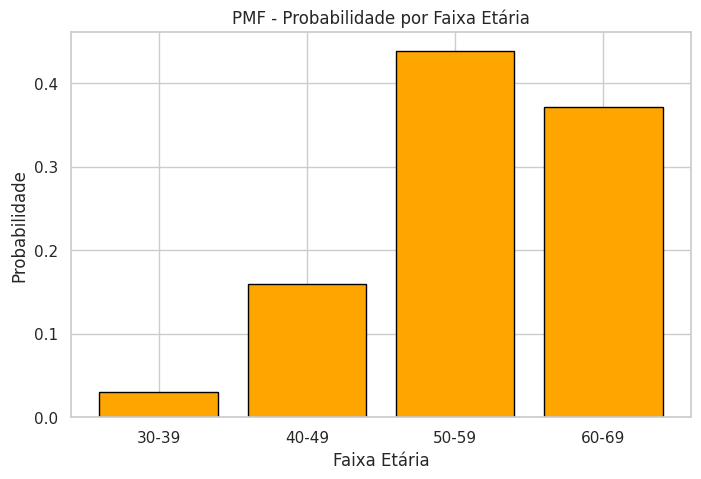

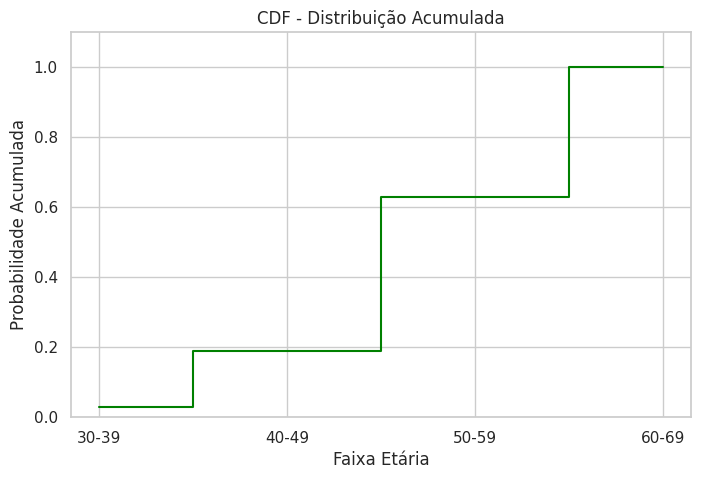


PROBLEMA APLICADO
Capacidade do hospital: 40 pacientes por dia
P(Y > 40): 0.685489183070397

INTERPRETAÇÃO:
Essa probabilidade representa a chance da demanda ultrapassar 40 pacientes.


In [ ]:
# Parte 3 - Variável Aleatória Discreta

# Criando faixas etárias

bins_idade = [30, 40, 50, 60, 70]
labels_idade = ['30-39', '40-49', '50-59', '60-69']

# Nova coluna categórica

df['faixa_etaria'] = pd.cut(df['age'],
bins=bins_idade,
labels=labels_idade,
right=False)

# Contagem de pacientes com target = 1

df_doenca = df[df['target'] == 1]

contagem = df_doenca['faixa_etaria'].value_counts().sort_index()

print('\nNúmero de pacientes com doença por faixa etária:')
print(contagem)

# Construção da PMF

total = contagem.sum()

pmf = contagem / total

print('\nFunção de Probabilidade (PMF):')
print(pmf)

# Esperança

valores_y = contagem.values
probabilidades = pmf.values

esperanca = np.sum(valores_y * probabilidades)

print(f'\nEsperança E(Y): {esperanca}')

# Variância

variancia_y = np.sum(((valores_y - esperanca) ** 2) * probabilidades)

print(f'Variância V(Y): {variancia_y}')

# CDF

cdf = pmf.cumsum()

print('\nFunção de Distribuição Acumulada (CDF):')
print(cdf)

# Gráfico da PMF

plt.figure(figsize=(8,5))
plt.bar(labels_idade, pmf.values, color='orange', edgecolor='black')
plt.title('PMF - Probabilidade por Faixa Etária')
plt.xlabel('Faixa Etária')
plt.ylabel('Probabilidade')
plt.show()

# Gráfico da CDF

plt.figure(figsize=(8,5))
plt.step(labels_idade, cdf.values, where='mid', color='green')
plt.title('CDF - Distribuição Acumulada')
plt.xlabel('Faixa Etária')
plt.ylabel('Probabilidade Acumulada')
plt.ylim(0, 1.1)
plt.show()

# Problema aplicado

print('\nPROBLEMA APLICADO')
print('Capacidade do hospital: 40 pacientes por dia')

# Modelo probabilístico simples

media_pacientes = esperanca

desvio = np.sqrt(variancia_y)

prob_maior_40 = 1 - stats.norm.cdf(40, loc=media_pacientes, scale=desvio)

print(f'P(Y > 40): {prob_maior_40}')

print('\nINTERPRETAÇÃO:')
print('Essa probabilidade representa a chance da demanda ultrapassar 40 pacientes.')

#Parte 4: Teste Qui-quadrado

In [ ]:
# Parte 4 - Teste Qui-Quadrado

from scipy.stats import chi2_contingency

# Tabela de contingência

tabela_contingencia = pd.crosstab(df['sex'], df['target'])

print('\nTabela de Contingência:')
print(tabela_contingencia)

# Teste qui-quadrado

qui2, p_valor, gl, esperados = chi2_contingency(tabela_contingencia)

print(f'\nQui-quadrado: {qui2}')
print(f'p-valor: {p_valor}')
print(f'Graus de liberdade: {gl}')

print('\nFrequências esperadas:')
print(esperados)

# Decisão para alpha = 0.05

alpha_1 = 0.05

if p_valor < alpha_1:

  print('\nPara α = 0.05: Rejeitamos H0')
else:
  print('\nPara α = 0.05: Não rejeitamos H0')

# Decisão para alpha = 0.10

alpha_2 = 0.10

if p_valor < alpha_2:

  print('Para α = 0.10: Rejeitamos H0')
else:
  print('Para α = 0.10: Não rejeitamos H0')

# Interpretação

print('\nINTERPRETAÇÃO:')
print('O teste verifica se existe associação entre sexo e presença de doença cardíaca.')




Tabela de Contingência:
target   0    1
sex            
0.0     70   25
1.0     88  111

Qui-quadrado: 21.284029993404726
p-valor: 3.960170305932011e-06
Graus de liberdade: 1

Frequências esperadas:
[[ 51.05442177  43.94557823]
 [106.94557823  92.05442177]]

Para α = 0.05: Rejeitamos H0
Para α = 0.10: Rejeitamos H0

INTERPRETAÇÃO:
O teste verifica se existe associação entre sexo e presença de doença cardíaca.


#Parte 5: Correlação com Pearson

In [ ]:
# Parte 5 - Correlação de Pearson

# Correlação de Pearson

coeficiente, p_pearson = stats.pearsonr(df['age'], df['thalach'])

print(f'\nCoeficiente de Pearson: {coeficiente}')
print(f'p-valor: {p_pearson}')

# Classificação da força da correlação

if abs(coeficiente) < 0.3:
  forca = 'fraca'
elif abs(coeficiente) < 0.7:
  forca = 'moderada'
else:
  forca = 'forte'

# Direção

if coeficiente > 0:
  direcao = 'positiva'
else:
  direcao = 'negativa'

print(f'\nA correlação é {forca} e {direcao}.')

# Teste de hipótese

alpha = 0.05

if p_pearson < alpha:
  print('Rejeitamos H0: existe correlação significativa.')
else:
  print('Não rejeitamos H0: não existe correlação significativa.')

# Interpretação

print('\nINTERPRETAÇÃO:')
print('O coeficiente de Pearson mede a intensidade da relação linear entre as variáveis.')



Coeficiente de Pearson: -0.38940890137257134
p-valor: 4.398699842909416e-12

A correlação é moderada e negativa.
Rejeitamos H0: existe correlação significativa.

INTERPRETAÇÃO:
O coeficiente de Pearson mede a intensidade da relação linear entre as variáveis.
